<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A missing template is not zero traffic

A NetFlow v9 data datagram names a template but does not repeat its field layout. Can structurally valid input still leave traffic counters unavailable? We decode a complete reference stream and a selectable stream, keep diagnostics visible, and compare the bytes we can actually account for.

**All inputs are unchanged synthetic golden datagrams from this repository.** They were generated in Rust, not captured from a live network. The embedded export clock, addresses, ports, counters and exporter labels are demonstration inputs. No collector, socket or external network data is used. Bundled provenance records byte hashes and the source revision.

## Choose whether the v9 template arrives

`INCLUDE_TEMPLATE` is a Boolean, default **True**. Both runs keep the same v5 and v9 data datagrams. Setting it to **False** withholds only the v9 template from the selected stream; a separate complete reference scan retains it for comparison. Restart and run all after changing the parameter. Capture order below is an explicit ordinal, not a measured timestamp.

In [1]:
INCLUDE_TEMPLATE = True  # withhold only the selected stream’s v9 template when False

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from notebook_support import finish, theme

assert type(INCLUDE_TEMPLATE) is bool
manifest = json.loads(Path("fixtures/provenance.json").read_text())
for item in manifest["files"]:
    assert hashlib.sha256((Path("fixtures") / item["file"]).read_bytes()).hexdigest() == item["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-netflow/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-netflow/notebooks/pyproject.toml.

## Inventory the captured datagrams

The literal release location downloads a pinned published worker. The INET extension supplies address types; no source checkout or local worker build is required. `read_blob` loads UDP payload bytes. The explicit exporter label scopes v9 templates together with observation domain and template ID. Real captures must preserve that identity and ordering.

A v5 datagram contains fixed-layout flow records. The v9 pair separates layout from data. The wire-size column counts export-payload bytes, which is a different quantity from traffic bytes inside decoded records.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL inet;
LOAD inet;
ATTACH 'netflow' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-netflow@v0.4.0');
CREATE TABLE captures AS
SELECT 1 AS capture_order,'edge-a' AS exporter,'v5 data' AS role,content AS datagram
FROM read_blob('fixtures/v5.dat')
UNION ALL SELECT 2,'edge-b','v9 template',content FROM read_blob('fixtures/v9_1template.dat')
UNION ALL SELECT 3,'edge-b','v9 data',content FROM read_blob('fixtures/v9_2data.dat');
CREATE TABLE inspection AS
SELECT capture_order,exporter,role,octet_length(datagram) AS payload_bytes,
 netflow.main.flow_version(datagram) AS version,netflow.main.well_formed(datagram) AS structure,
 netflow.main.header(datagram) AS header,
 role<>'v9 template' OR {{INCLUDE_TEMPLATE}} AS selected
FROM captures;

,Count


In [4]:
%%sql inventory <<
SELECT capture_order,exporter,role,payload_bytes,version,structure.ok AS structurally_valid,
 header.obs_domain AS observation_domain,header.export_time AT TIME ZONE 'UTC' AS synthetic_export_utc,selected
FROM inspection ORDER BY capture_order;

In [5]:
display(inventory)

,capture_order,exporter,role,payload_bytes,version,structurally_valid,observation_domain,synthetic_export_utc,selected
0,1,edge-a,v5 data,120,5,True,1,2023-11-14 22:13:20,True
1,2,edge-b,v9 template,56,9,True,1,2023-11-14 22:13:20,True
2,3,edge-b,v9 data,45,9,True,1,2023-11-14 22:13:20,True


## Decode two independent scans

Pass the ordered input relation to `flows((FROM ...))`; this is a table-in-out decoder, not a correlated scalar call. Each scan carries its own template state across input rows. A template seen in a different SQL execution does not prime this scan. The worker’s separate `templates()` projection is historical introspection, so we do not treat it as evidence that this particular scan received a template.

Materialize both decodes once. A missing-template result is a diagnostic row with unavailable flow fields, not a decoded zero-byte flow. The reference scan deliberately retains complete inputs so we can distinguish a visibility change from a change to the synthetic traffic reports.

In [6]:
%%sql
CREATE TABLE reference_rows AS
SELECT * FROM netflow.main.flows((FROM(SELECT datagram,exporter FROM captures ORDER BY capture_order)));
CREATE TABLE selected_rows AS
SELECT * FROM netflow.main.flows((FROM(SELECT datagram,exporter FROM captures
 WHERE role<>'v9 template' OR {{INCLUDE_TEMPLATE}} ORDER BY capture_order)));
CREATE TABLE outcomes AS
SELECT 'Complete reference' AS scenario,* FROM reference_rows
UNION ALL SELECT 'Selected stream',* FROM selected_rows;
CREATE TABLE accounting AS
SELECT scenario,count(*) FILTER(WHERE diagnostics IS NULL) AS decoded_flow_rows,
 count(*) FILTER(WHERE diagnostics IS NOT NULL) AS diagnostic_rows,
 sum(bytes) FILTER(WHERE diagnostics IS NULL) AS known_traffic_bytes,
 sum(packets) FILTER(WHERE diagnostics IS NULL) AS known_reported_packets
FROM outcomes GROUP BY scenario;

,Count


In [7]:
%%sql rows <<
SELECT exporter,flow_version,obs_domain,template_id,src_addr::INET::VARCHAR AS source_address,
 dst_addr::INET::VARCHAR AS destination_address,dst_port,bytes AS traffic_bytes,packets,diagnostics
FROM selected_rows ORDER BY exporter,dst_port;

In [8]:
display(rows)

,exporter,flow_version,obs_domain,template_id,source_address,destination_address,dst_port,traffic_bytes,packets,diagnostics
0,edge-a,5,1,<NA>,192.168.1.1,8.8.8.8,53,200,2,None
1,edge-a,5,1,<NA>,10.0.0.1,10.0.0.2,80,1000,10,None
2,edge-b,9,1,256,10.1.1.1,10.1.1.2,443,800,5,None


## Count decoded outcomes without hiding failures

The first chart keeps decoded flow rows separate from diagnostic rows. Neither count is a count of network packets, and one unresolved Data Set may contain an unknown number of flow records. We never turn a diagnostic-row count into an estimated missing-flow count. The fixed-layout v5 stream provides a control that should remain unchanged.

In [9]:
%%sql totals <<
SELECT * FROM accounting ORDER BY CASE scenario WHEN 'Complete reference' THEN 0 ELSE 1 END;

,scenario,decoded_flow_rows,diagnostic_rows,known_traffic_bytes,known_reported_packets
0,Complete reference,3,0,2000.0,17.0
1,Selected stream,3,0,2000.0,17.0


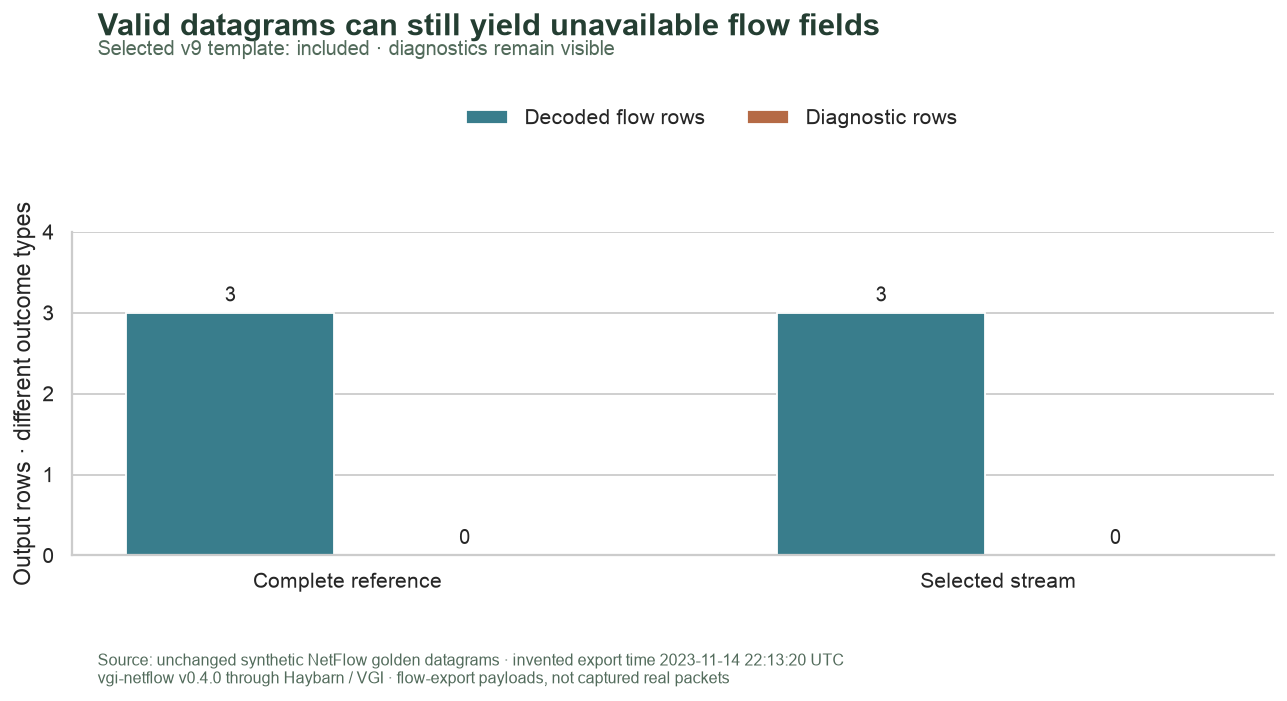

In [10]:
display(totals)
fig, ax = plt.subplots(figsize=(10.5, 5.4))
x = list(range(len(totals)))
for col, offset, color, label in [
    ("decoded_flow_rows", -0.18, "#397d8c", "Decoded flow rows"),
    ("diagnostic_rows", 0.18, "#b56a45", "Diagnostic rows"),
]:
    bars = ax.bar([v + offset for v in x], totals[col], width=0.32, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_xticks(x, totals.scenario)
ax.set_ylabel("Output rows · different outcome types")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(0, max(totals.decoded_flow_rows.max(), totals.diagnostic_rows.max()) + 1)
ax.grid(axis="x", visible=False)
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False)
finish(
    fig,
    f"outcomes-template-{INCLUDE_TEMPLATE}",
    "Valid datagrams can still yield unavailable flow fields",
    f"Selected v9 template: {'included' if INCLUDE_TEMPLATE else 'withheld'} · diagnostics remain visible",
)

## Sum only decoded traffic counters

Aggregate clean rows by exporter and destination port. The complete reference defines the comparison categories. A missing selected aggregate remains **NULL** and receives an “unavailable” label, not a zero-height traffic bar. Ports are identifiers here; they do not prove which application generated traffic. The byte counters are exported fixture values, not payload sizes or a measured bandwidth rate.

In [11]:
%%sql
CREATE TABLE port_comparison AS
WITH complete AS(
 SELECT exporter,dst_port,sum(bytes) AS traffic_bytes FROM reference_rows WHERE diagnostics IS NULL GROUP BY exporter,dst_port),
 selected AS(
 SELECT exporter,dst_port,sum(bytes) AS traffic_bytes FROM selected_rows WHERE diagnostics IS NULL GROUP BY exporter,dst_port)
SELECT c.exporter,c.dst_port,c.traffic_bytes AS reference_bytes,s.traffic_bytes AS selected_bytes
FROM complete c LEFT JOIN selected s USING(exporter,dst_port) ORDER BY c.exporter,c.dst_port;

,Count


In [12]:
%%sql by_port <<
SELECT * FROM port_comparison ORDER BY exporter,dst_port;

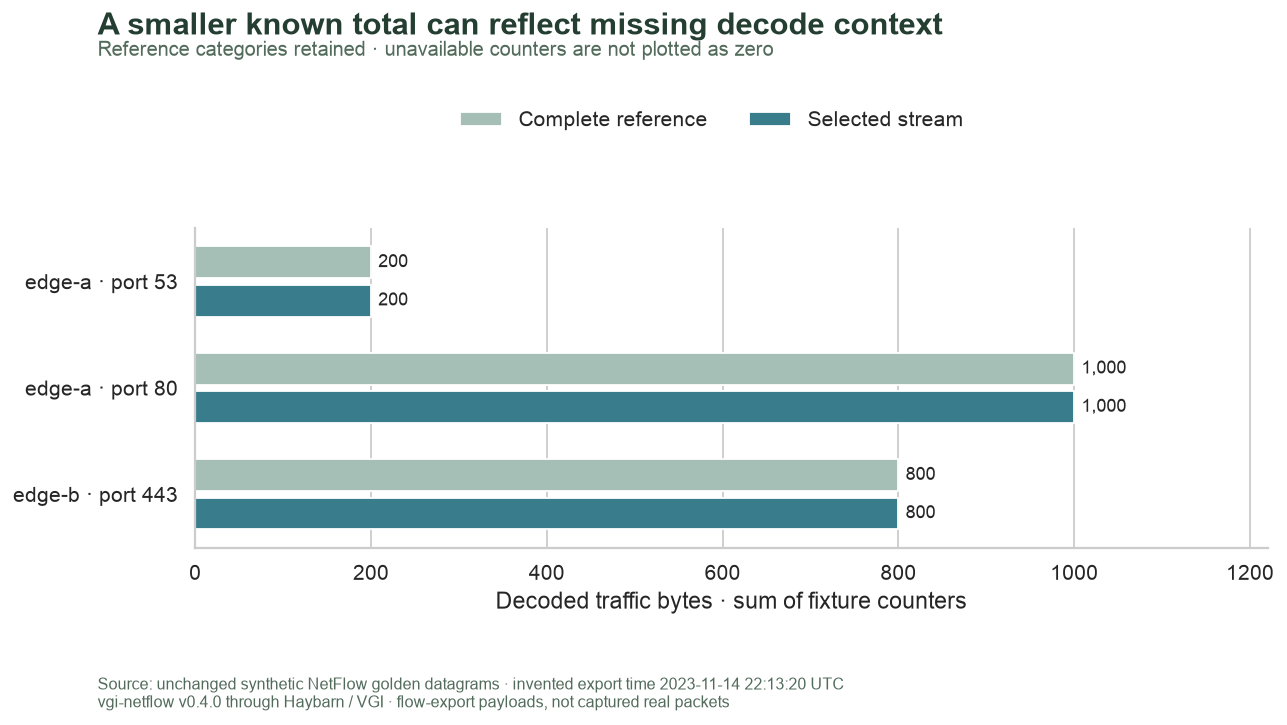

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))
y = list(range(len(by_port)))
ref = ax.barh([v - 0.18 for v in y], by_port.reference_bytes, height=0.3, color="#a5bfb6", label="Complete reference")
ax.bar_label(ref, labels=[f"{value:,.0f}" for value in by_port.reference_bytes], padding=4, fontsize=10)
for i, row in enumerate(by_port.itertuples()):
    if row.selected_bytes == row.selected_bytes:
        bar = ax.barh(
            i + 0.18, row.selected_bytes, height=0.3, color="#397d8c", label="Selected stream" if i == 0 else None
        )
        ax.bar_label(bar, labels=[f"{row.selected_bytes:,.0f}"], padding=4, fontsize=10)
    else:
        ax.text(15, i + 0.18, "Unavailable · see diagnostic", va="center", color="#9b5738", fontsize=10)
ax.set_yticks(y, [f"{r.exporter} · port {r.dst_port}" for r in by_port.itertuples()])
ax.set_ylim(len(by_port) - 0.5, -0.5)
ax.set_xlabel("Decoded traffic bytes · sum of fixture counters")
ax.set_xlim(0, float(by_port.reference_bytes.max()) * 1.22)
ax.grid(axis="y", visible=False)
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False)
finish(
    fig,
    f"traffic-template-{INCLUDE_TEMPLATE}",
    "A smaller known total can reflect missing decode context",
    "Reference categories retained · unavailable counters are not plotted as zero",
)

In [14]:
selected = totals[totals.scenario == "Selected stream"].iloc[0]
reference = totals[totals.scenario == "Complete reference"].iloc[0]
missing = int(selected.diagnostic_rows)
known = int(selected.known_traffic_bytes)
reference_bytes = int(reference.known_traffic_bytes)
selected_inputs = int(inventory.selected.sum())
display(
    Markdown(
        f"All **{selected_inputs} selected datagrams** are structurally valid. "
        f"The selected scan returns **{int(selected.decoded_flow_rows)} decoded flow rows** "
        f"and **{missing} diagnostic row{'s' if missing != 1 else ''}**. "
        f"Its known byte total is **{known:,}**, compared with **{reference_bytes:,}** in the complete reference: "
        f"a difference of **{reference_bytes - known:,} bytes**. "
        + (
            "The difference is explained by withholding decode context while leaving both data datagrams unchanged. "
            "It is not evidence of less network traffic; "
            "without the complete reference, the diagnostic alone would not reveal the missing byte count."
            if missing
            else "The selected scan received the template and matches the complete reference. "
            "Withholding it is the next experiment."
        )
    )
)

All **3 selected datagrams** are structurally valid. The selected scan returns **3 decoded flow rows** and **0 diagnostic rows**. Its known byte total is **2,000**, compared with **2,000** in the complete reference: a difference of **0 bytes**. The selected scan received the template and matches the complete reference. Withholding it is the next experiment.

## Check bytes, identity and scan isolation

The checks validate structural input, the unchanged v5 control, complete-reference counters and the selected stream’s relationship to that reference. Diagnostic rows must leave unavailable counters NULL. The experiment specifically tests that decoding the complete reference first cannot silently supply the selected scan’s missing template.

In [15]:
%%sql checks <<
SELECT 'all synthetic datagrams pass structural validation' AS check_name,bool_and(structure.ok) AS passed FROM inspection
UNION ALL SELECT 'selection changes only template presence',count(*) FILTER(WHERE selected)=count(*)-CASE WHEN {{INCLUDE_TEMPLATE}} THEN 0 ELSE 1 END FROM inspection
UNION ALL SELECT 'both data datagrams remain selected',bool_and(selected) FROM inspection WHERE role<>'v9 template'
UNION ALL SELECT 'complete reference has no diagnostic rows',count(*) FILTER(WHERE diagnostics IS NOT NULL)=0 FROM reference_rows
UNION ALL SELECT 'v5 header count matches its decoded records',
 (SELECT header.count FROM inspection WHERE version='5')=(SELECT count(*) FROM reference_rows WHERE flow_version='5')
UNION ALL SELECT 'fixed-layout v5 rows remain unchanged',count(*)=0 FROM(
 (SELECT * FROM reference_rows WHERE flow_version='5' EXCEPT ALL SELECT * FROM selected_rows WHERE flow_version='5')
 UNION ALL(SELECT * FROM selected_rows WHERE flow_version='5' EXCEPT ALL SELECT * FROM reference_rows WHERE flow_version='5'))
UNION ALL SELECT 'decoded counters and addresses are available',bool_and(bytes IS NOT NULL AND packets IS NOT NULL AND bytes>=0 AND packets>=0 AND src_addr IS NOT NULL AND dst_addr IS NOT NULL) FROM outcomes WHERE diagnostics IS NULL
UNION ALL SELECT 'diagnostics keep unknown counters NULL',coalesce(bool_and(bytes IS NULL AND packets IS NULL AND src_addr IS NULL AND dst_addr IS NULL),true) FROM selected_rows WHERE diagnostics IS NOT NULL
UNION ALL SELECT 'v9 decode depends on this scans template',
 CASE WHEN {{INCLUDE_TEMPLATE}} THEN count(*) FILTER(WHERE diagnostics IS NULL)>0 AND count(*) FILTER(WHERE diagnostics IS NOT NULL)=0
 ELSE count(*) FILTER(WHERE diagnostics LIKE 'missing-template:%')>0 AND count(*) FILTER(WHERE diagnostics IS NULL)=0 END
 FROM selected_rows WHERE flow_version='9'
UNION ALL SELECT 'known byte sum equals grouped clean counters',
 (SELECT known_traffic_bytes FROM accounting WHERE scenario='Selected stream')=(SELECT sum(selected_bytes) FROM port_comparison)
UNION ALL SELECT 'selected clean counters agree with complete reference',count(*)=0 FROM(
 SELECT exporter,src_addr,dst_addr,src_port,dst_port,bytes,packets FROM selected_rows WHERE diagnostics IS NULL
 EXCEPT ALL SELECT exporter,src_addr,dst_addr,src_port,dst_port,bytes,packets FROM reference_rows WHERE diagnostics IS NULL);

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} checks** pass. "
        "Input validity, decode availability and traffic counters have separate accounting."
    )
)

,check_name,passed
0,all synthetic datagrams pass structural valida...,True
1,selection changes only template presence,True
2,both data datagrams remain selected,True
3,complete reference has no diagnostic rows,True
4,v5 header count matches its decoded records,True
5,fixed-layout v5 rows remain unchanged,True
6,decoded counters and addresses are available,True
7,diagnostics keep unknown counters NULL,True
8,v9 decode depends on this scans template,True
9,known byte sum equals grouped clean counters,True


All **11 checks** pass. Input validity, decode availability and traffic counters have separate accounting.

## Try one change

Change `INCLUDE_TEMPLATE` from **True** to **False**, restart and run all. Predict that the v5 control stays identical, the v9 data datagram remains structurally valid, and its traffic counter becomes unavailable with a missing-template diagnostic. Compare both charts and the known byte total. The complete reference reveals what this synthetic example withheld; it is not a general estimator for missing traffic. Restore **True** for the saved default.

This tiny scan does not test template expiration, packet loss rates, exporter restarts or large-scale buffering. A real archive needs correct exporter/domain identity, ordering and coverage before its decoded totals can be interpreted.

In [17]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>